---
title: "Expectation Maximization und gemischte Gauss-Modelle"
short_title: "Expectation Maximization"
description: "Maximum Likelihood in Modellen mit latenten Variablen: gemischte Gaussche Modelle supervised und unsupervised, die Ungleichung von Jensen und der EM-Algorithmus."
---

[Vorlesungsaufzeichnung Expectation Maximization (VL 23)](https://media.hhu.de/channel/video/data-science-vl-23-expectation-maximization-2025/e3186d8384176340f294ecf2b52c1025/167)
[Anwendung von EM (VL 24)](https://media.hhu.de/channel/video/data-science-vl-24-anwendung-von-em-2025/5997aad6bc586be623998b7954f5449c/167)

## Motivation

Im supervised Learning haben wir gesehen, dass Lineare Regression (eventuell mit einem Kernel) uns helfen könnte, Daten zu klassifizieren. Beim unsupervised Learning haben wir zur Klassifikation k-Means und Kernel-k-Means eingesetzt, jeweils ergänzt durch Datenskalierung und Hauptachsentransformation. Dabei haben wir gute Ergebnisse gesehen, wenn die Cluster im Feature-Raum konvex und gut approximierbar mit einer Normalverteilung ohne Kovarianz (also gut approximierbar durch Vollkugeln) waren. Wenn die Cluster aber zwar normalverteilt aber mit unterschiedlicher Kovarianz waren, und nicht linear voneinander getrennt werden konnten, haben wir keine guten Ergebnisse mit k-Means gesehen.

```{admonition} Beispiel
Formuliert als Expectation-Maximization-Verfahren ist das k-Means-Verfahren:
  
1. Initialisierung (Clustermittelpunkte festlegen)  
2. Iterativ bis zur Konvergenz der Clustermittelpunkte:  
   a. (E-Schritt): Punkte dem jeweils nächsten Clustermittelpunkt zuteilen und so zu einer Klasseneinteilung kommen  
   b. (M-Schritt): Neue Clustermittelpunkte als Mittelwert aller Elemente einer Klasse festlegen  
   
Der E-Schritt (Expectation) heißt so, weil wir unsere Erwartung über den Wert der latenten Variable updaten.

Der M-Schritt (Maximization) heißt so, weil wir eine Fitness-Funktion maximieren - konkret minimieren wir die Summe der quadrierten Abstände der Punkte zu den ihnen zugeteilten Clustermittelpunkten.
```

Es liegt nahe, ein Verfahren zu verwenden, welches die Form der Cluster berücksichtigt.

### Gemischte Gausssche Modelle, supervised

Wenn wir von Daten in $\mathbb{R}^d$ Einteilungen in $k$ Klassen (Label) gegeben haben, können wir für jeden Teildatensatz aller Punkte einer Klasse die Sample-Kovarianz und den Sample-Erwartungswert ausrechnen und damit eine $d$-variate Normalverteilung aufstellen, die diesen Teildatensatz modelliert.

Daraus resultiert ein Modell für die gesamten Daten, wenn wir mit $p_i$ die Anzahl der Punkte in Klasse $i$ geteilt durch die Anzahl an Punkten im Sample insgesamt bezeichnen und mit $f_i(x)$ die geschätzte Dichte der Normalverteilung von Klasse $i$, nämlich die Dichte

$$
f(x) = \sum_{i=1}^k p_i f_i(x).
$$

Dieses Modell können wir natürlich auch wieder benutzen, um einzuschätzen, zu welcher Klasse ein Punkt gehört. Dazu berechnen wir für einen Punkt $x$ die Dichten

$$
P_i(x) = p_i f_i(x)
$$

und wählen das $i$ aus, für das dieser Ausdruck maximal wird.

Als Entstehungsprozess kann man sich das so vorstellen: ein (fiktives) gemischtes Gausssches Modell wurde verwendet um die Datenpunkte zu sampeln, indem zunächst nach der diskreten Verteilung der $p_i$ eine Klasse $j$ ausgewählt wurde und dann mit der Dichte $f_j(x)$ ein Sample daraus gezogen wurde, und das so oft, wie es Datenpunkte gibt.

Nun kann es leicht passieren, wenn sich die Cluster überschneiden, dass manche Punkte $x$ durch das Modell anders klassifiziert werden, als dies ursprünglich der Fall war -- dagegen gibt es kein grundsätzliches Gegenmittel. Dennoch können wir so das am besten an die Daten angepasste gemischte Gausssche Modell bestimmen und damit Daten sampeln, die den vorliegenden sehr ähnlich sehen werden (vorausgesetzt die Normalverteilungsannahme war korrekt).

Wir wollen noch eine weitere Beobachtung machen: das gemischte Gausssche Modell gibt uns mehr als nur eine neue Klasseneinteilung, sondern zu jedem Punkt zu jeder Klasse eine Wahrscheinlichkeit dafür, dass der Punkt zu dieser Klasse gehört. Das ist wesentlich mehr Information und kann deutlich nützlicher sein. Vor allem bei den nicht korrekt klassifizierten Punkten erhalten wir damit eine Möglichkeit, unsere Gewissheit bei der Klasseneinteilung zu quantifizieren.

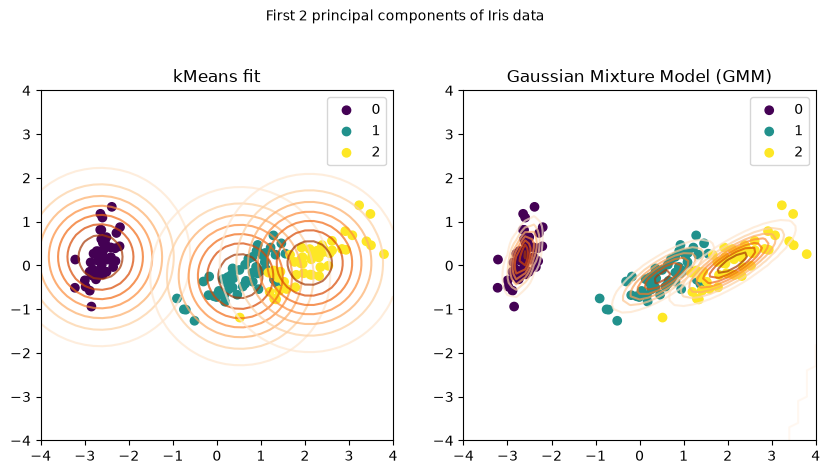

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from scipy.stats import multivariate_normal as mvn

x, y = load_iris(return_X_y=True)
# work in principal components, to plot later in the first two:
xpc = PCA().fit_transform(x)

k = 3
assert k == np.max(y) + 1

mvns = list(range(k))
for i in range(k):
    # for simplicty, take only first 2 PCs here:
    mu = np.mean(xpc[y == i][:,:2], axis=0)
    sigma = np.cov(xpc[y == i][:,:2], rowvar=False)
    mvns[i] = mvn(mean=mu, cov=sigma, allow_singular=True)

round_mvns = list(range(k))
for i in range(k):
    mu = np.mean(xpc[y == i][:,:2], axis=0)
    sigma = np.eye(2)
    round_mvns[i] = mvn(mean=mu, cov=sigma, allow_singular=True)
    
fig = plt.gcf()
fig.set_size_inches(10, 10)
ax1 = plt.subplot(221)
ax2 = plt.subplot(222, sharex=ax1, sharey=ax1)
plt.figtext(0.35, 0.95, "First 2 principal components of Iris data")
ax1.set_title("kMeans fit")
ax2.set_title("Gaussian Mixture Model (GMM)")
xs, ys = np.mgrid[-4:4.1:.2, -4:4.1:.1]
for i in range(k):
    zs = round_mvns[i].pdf(np.dstack((xs, ys)))
    ax1.contour(xs, ys, zs,
                cmap=plt.cm.Oranges, alpha=.7)
    ax1.scatter(xpc[y == i][:,0], xpc[y == i][:,1],
                c=np.ones_like(y[y == i])*i, vmin=0, vmax=k-1,
                label=str(i))
    zs = mvns[i].pdf(np.dstack((xs, ys)))
    ax2.contour(xs, ys, zs,
                cmap=plt.cm.Oranges, alpha=.7)
    ax2.scatter(xpc[y == i][:,0], xpc[y == i][:,1],
                c=np.ones_like(y[y == i])*i, vmin=0, vmax=k-1,
                label=str(i))
ax1.legend()
ax2.legend()
plt.show()

### Gemischte Gausssche Modelle, unsupervised

Das eben beschriebene Vorgehen ist nicht möglich, wenn wir keine Klasseneinteilung vorgegeben haben.
In diesem Fall ist die Klasse eine **latente Variable**, die wir nicht kennen, die aber in der Modellbeschreibung wesentlich ist.
Was wir gut modellieren können, sind bedingte Wahrscheinlichkeiten, wenn wir auf den Wert der latenten Variable bedingen - also die Verteilung einer einzelnen Klasse. Die Verteilung der latenten Variable ist schwieriger zu beschreiben, wenn wir nur ungelabelte Daten zur Verfügung haben.

Es bietet sich ein zweistufiges Verfahren an: zunächst ließe sich mit k-Means eine Klasseneinteilung finden (die oftmals nicht besonders gut ist, wenn die Homoskedastizitätsvoraussetzung nicht erfüllt ist) und dann auf Grundlage dieser Klasseneinteilung ein gemischtes Gausssches Modell aufstellen, d.h. eine Schätzung der latenten Variable gewinnen.

Nun lässt sich wiederum feststellen, dass die Klasseneinteilung, die uns das gemischte Modell berechnen lässt, im Allgemeinen von der Klasseneinteilung abweicht, die wir zuvor mit k-Means berechnet haben. Diesmal aber ist naheliegend, dass das gemischte Modell eine bessere Klasseneinteilung leistet, denn nun werden ja zusätzlich die Formen der Cluster berücksichtigt (approximiert durch Ellipsoide aufgrund der Normalverteilungsannahme).

Mit dieser verbesserten Klasseneinteilung, also der verbesserten Schätzung der latenten Variable, kann man nun erneut ein gemischtes Gaussches Modell aufsetzen, d.h. die Kovarianzmatrizen und Mittelpunkte neu schätzen, ganz ähnlich zum Iterationsschritt im k-Means-Verfahren.

Wir wollen nun noch eine Beobachtung machen: Wenn im Aufstellen der Kovarianzmatrizen jeweils nur die Güte des Modells für eine einzelne Klasse betrachtet wird (also der beste Fit), dann berücksichtigen wir nicht die Auswirkung dieser Modelländerung auf die anderen Klassen - die wird es aber meist geben.
Es wäre also besser, im Iterationsschritt simultan alle Parameter zu optimieren auf die Zielgröße - das gemischte Modell mit dem besten Fit.

Um für eine beliebige Verteilung einen guten Schätzer zu konstruieren, haben wir das Maximum-Likelihood-Verfahren genutzt, und das wollen wir auch im Fall einer Mischung von Normalverteilungen versuchen.

## Maximum Likelihood in Modellen mit latenten Variablen

Die Wahrscheinlichkeitsdichte im gemischten Gausschen Modell, wo $\theta_j$ die Parameter $\mu_j,\Sigma_j$ bezeichnet einer einzelnen Mischkomponente, und $p_j$ die Verteilung der Komponenten, ist

$$
f(x) = \sum_{j=1}^k p_j f_j(x, \theta_j) = P(X=x|M=\theta) = L(\theta),
$$

das ist die Likelihood (also die Wahrscheinlichkeit der Daten, berechnet in unserem Modell), wenn wir mit $M$ unser Modell bezeichnen und mit $X$ die Daten. Die Modellannahme ist jetzt also: $X$ ist mit $f$ verteilt. Dabei ist $\theta$ die Menge an Parametern $p_j$ zusammen mit den Parametern $\mu_j,\Sigma_j$, die in $f_j$ versteckt sind. Wenn wir diese Größe als Likelihood auffassen, dann als Funktion in diesen Parametern.

Tipp: wenn Sie sich gern in der Notation $\theta$ als Liste über $\theta_j$ vorstellen wollen, setzten Sie einfach $\theta_0 := (p_1,\dots,p_k)$.

Wenn wir die Modellierung, dass die Einteilung der Datenpunkte in Klassen, durch Wahrscheinlichkeiten ausgedrückt werden, ernst nehmen, können wir auch gleich die Einteilung als Zufallsvariable $Y$ modellieren. Es ist also $Y_i = j$ wenn der $i$-te Datenpunkt von Klasse $j$ ist, aber wir kennen die Variable $Y$ nicht.

Unser Modell, formuliert mit der latenten Variable $Y$, ist

$$
\begin{aligned}
P(Y = j\ |\ \theta)      =& p_j \\
P(X=x\   |\ Y=j, \theta) =& f_j(x,\ \mu_j,\Sigma_j) \\
P(X=x\   |\ \theta)      =& \sum_{j=1}^k P(X=x,\ Y=j\ |\ \theta) \\
                         =& \sum_{j=1}^k P(Y = j\ |\ \theta)\, P(X=x\ |\ Y=j, \theta).
\end{aligned}
$$

### Nullstellen der Ableitung bestimmen?

Direkt die Nullstellen der Ableitung von $L(\theta)$ zu bestimmen ist nicht leicht, aber auch der beliebte Trick, $\ell(\theta) = \log L(\theta)$ zu maximieren, bringt hier nicht viel, denn

$$
\begin{aligned}
\ell(\theta) =& \log P(X=x\ |\ \theta) \\
             =& \log \left( \sum_{j=1}^k P(X=x, Y=j\ |\ \theta)  \right) \\
             =& \log \left( \sum_{j=1}^k p_j f_j(x\ |\ \theta_j) \right)
\end{aligned}
$$

und aus der Summen-Nummer kommen wir mit dem Logarithmus nicht so leicht raus.

### Jensen to the rescue!

Wir können unsere Ziele etwas abschwächen und mit der Jensenschen Ungleichung arbeiten (denn der Logarithmus ist konkav und $\sum_{j=1}^k p_j = 1$):

$$
\ell(\theta) \geq \sum_{j=1}^k p_j \log f_j(x\ |\ \theta_j)
$$

Das charmante an dem Ausdruck auf der rechten Seite ist, dass ein $\theta$, welches die rechte Seite maximiert, keine kleinere linke Seite haben kann. In Formeln: wenn wir ein $\theta^{(t)}$ gegeben haben, dann ein $\theta^{(t+1)}$ bestimmen, für dass die rechte Seite größer wird, dann ist auch $\ell(\theta^{(t+1)}) \geq \ell(\theta^{(t)})$.

Wir wollen feststellen, dass sich im Ausdruck für den Beitrag einer Klasse $p_j f_j$ auch eine fette $1 = \frac{q(j)}{q(j)}$ hinein multiplizieren lässt, hier

$$
\begin{aligned}
\ell(\theta) =& \log \left( \sum_{j=1}^k P(X=x, Y=j\ |\ \theta) \right) \\
             =& \log \left( \sum_{j=1}^k q(j) \frac{P(X=x, Y=j\ |\ \theta)}{q(j)} \right).
\end{aligned}
$$

Die Nützlichkeit sieht man nach Anwenden der Jensenschen Ungleichung, diesmal auf die Konvexkombination $\sum_{j=1}^k q(j) = 1$, wobei wir ab jetzt also annehmen, dass $q$ eine Wahrscheinlichkeitsdichte ist: 

$$
\begin{aligned}
\ell(\theta) \geq & \sum_{j=1}^k q(j) \log \left( \frac{P(X=x, Y=j\ |\ \theta)}{q(j)} \right) =: L(\theta,q) \\
                = & \sum_{j=1}^k q(j) \left( \log \left( P(X=x, Y=j\ |\ \theta \right) - \log q(j) \right) \\
                = & \sum_{j=1}^k q(j) \log P\left(X=x, Y=j\ |\ \theta\right) \qquad - \sum_{j=1}^k q(j) \log q(j) \\
                = & \sum_{j=1}^k q(j) \log P\left(X=x, Y=j\ |\ \theta\right) \qquad + H(q).
\end{aligned}
$$

Wir haben also eine untere Schranke an $\ell(\theta)$ gefunden, die wir schreiben können als Summe eines Ausdrucks, der leichter zu berechnen ist, und der Entropie der Verteilung mit Dichte $q$. Da die Entropie nicht von $\theta$ abhängt, lässt sich $L(\theta,q)$ durch maximieren des anderen Summanden maximieren.

```{admonition} Bemerkung
In der Vorlesung *Einführung in Deep Learning* heißt genau diese untere Schranke $L(\theta,q)$ *ELBO* (evidence lower bound; die *Evidenz* ist $P(X=x\ |\ \theta)$). Sie ist dort das Trainingsziel von *Variational Autoencoders*, bei denen die Verteilung $q$ der latenten Variable von einem neuronalen Netz ausgegeben wird.
```

Diese Beobachtung wollen wir wieder aufgreifen (daher haben wir dem Kind auch einen Namen $L(\theta,q)$ gegeben), aber jetzt erstmal einen allgemeinen Lösungsansatz diskutieren.

## Auxiliary Functions

Wenn wir eine Funktion $\ell(\theta)$ nicht maximieren können,
können wir versuchen, behelfsmäßig so zu tun als sei $\theta$ in einigen Teilausdrücken von $\ell(\theta)$ konstant, dann maximieren, und dann die anderen Teilausdrücke konstant halten bzw. darüber maximieren. Um das zu formalisieren, führen wir eine Hilfsfunktion $Q(\theta,\vartheta)$ ein, die leichter in $\theta$ zu maximieren ist als $\ell$, aber dennoch $Q(\theta, \theta) = \ell(\theta)$ erfüllt und außerdem $Q(\theta,\vartheta) \leq \ell(\theta)$ für alle $\vartheta$ erfüllt.

Mit diesen Voraussetzungen kann man bereits zeigen, dass ein iterativer Prozess zu immer besseren Approximationen $\theta^{(t)}$ an das $\theta$, welches $\ell(\theta)$ maximiert, führt. Dabei bezeichnen wir mit $\theta^{(t+1)}$ das $\theta$ sodass $Q(\theta, \theta^{(t)})$ maximal wird (nach Annahme finden wir das leicht).

$$
\begin{aligned}
\ell(\theta^{(t)}) =& Q(\theta^{(t)}, \theta^{(t)}) \\
               \leq & Q(\theta^{(t+1)}, \theta^{(t)}) \text{ (M-Schritt)} \\
               \leq & Q(\theta^{(t+1)}, \theta^{(t+1)}) \text{ (E-Schritt)} \\
                    &  = \ell(\theta^{(t+1)}).
\end{aligned}
$$

Insgesamt haben wir also $\ell(\theta^{(t)}) \leq \ell(\theta^{(t+1)})$, d.h. zumindest verschlechtern wir uns dabei nicht mit unserer Schätzung!

Es bleibt für uns, wenn wir diesen Ansatz wählen wollen, noch die Wahl einer geschickten Hilfsfunktion $Q(\theta,\vartheta)$.


## Vollständige-Daten log-Likelihood

Die letzte Zutat zur Entwicklung des E-M-Algorithmus für das gemischte Gausssche Modell ist die vollständige-Daten-log-Likelihood. Das ist die log-Likelihood in der fiktiven Welt, in der wir tatsächlich die vollständigen Daten, d.h. nicht nur die Werte von $X$ sondern auch die der latenten Variable $Y$, also die tatsächlichen Klassen der Datenpunkte kennen.

Die vollständigen Daten sind also $(x_i,y_i)$, was wir mit $(X,Y)$ modellieren.

Es ist nun nützlich, die Variable $Y_i$ auch one-hot-encoded anzusehen: $Y_{ij} = 1$ wenn $Y_i = j$ und $Y_{ij} = 0$, wenn $Y_i \neq j$. Manche schreiben dafür auch $[Y_i=j]$ (Iversen-Bracket).

Die log-Likelihood der Daten unter dem gemischten Gaussschen Modell ist

$$
\begin{aligned}
\ell_c(\theta) = \log P((X,Y)|\theta) =& \sum_{i=1}^n \log P(X=x_i, Y=y_i\ |\ \theta) \\
                                       & \sum_{i=1}^n \log \prod_{j=1}^k {P(X=x_i, Y=j\ |\ \theta)}^{Y_{ij}} \\
                                       & \sum_{i=1}^n \sum_{j=1}^k Y_{ij} \log P(X=x_i, Y=j\ |\ \theta)
\end{aligned}
$$

dabei haben wir in der ersten Umformung eine fette $1$ hinzugefügt, da $Y_{ij}$ nur für einen Faktor in dem Produkt $\prod_{j=1}^k (...)^{Y_{ij}}$ überhaupt $1$ ist, ansonsten $0$, und damit der entsprechende Faktor $1$.
Die zweite Umformung ist nur $\log \prod (...)^t = \sum t \log (...)$.

Man beachte auch, dass das $\theta$ jetzt wirklich nur noch $\theta_1,\dots,\theta_k$ ist, denn die $p_i$ sind in der Verteilung von $Y$ kodiert.

Wir können noch weiter vereinfachen:

$$
\log P(X=x_i, Y=y_i) = \log \left( p_{y_i} f_{y_i}(x_i) \right) = \log p_{y_i} + \log f_{y_i}(x_i)
$$

### Erwartungswert über die latente Variable

Wenn wir eine Verteilung $q(y)$ für die latente Variable $Y$ annehmen, dann können wir den Erwartungswert über diese bilden:

$$
\begin{aligned}
\mathbb{E}_{Y \sim q} \ell_c(\theta) =& \mathbb{E}_{Y \sim q} \left( \sum_{i=1}^n \sum_{j=1}^k Y_{ij} \left( \log p_{y_i} + \log f_{y_i}(x_i\ |\ \theta_{y_i}) \right) \right) \\
 =& \sum_{i=1}^n \sum_{j=1}^k \mathbb{E}_{Y \sim q} Y_{ij} \left( \log p_{j} + \log f_{j}(x_i\ |\ \theta_j) \right) \\
 =& \sum_{i=1}^n \sum_{j=1}^k \tau_{ij} \left( \log p_{j} + \log f_{j}(x_i\ |\ \theta_j) \right).
\end{aligned}
$$

Hierbei nennen wir die mit $\tau_{ij}$ bezeichneten Terme **responsibilites** oder **Verantwortlichkeiten**, denn sie sind in unserem Modell verantwortlich für die Einteilung der Punkte $x_i$ in Klassen:

$$
\tau_{ij} := \mathbb{E}_{Y \sim q} Y_{ij} = P(Y_i = j\ |\ X=x_i,\theta) = \frac{P(Y_i = j,\ X=x_i\ |\ \theta)}{P(X=x_i\ |\ \theta)}
$$

Wenn wir die $\tau_{ij}$ festhalten, haben wir mit $\mathbb{E}_{Y \sim q} \ell_c(\theta)$ eine Größe, die wir maximieren können (auch wenn die $\tau_{ij}$ natürlich eigentlich von $\theta$ abhängen). Wir wollen die $\tau_{ij}$ als Funktion von $\theta$ betrachten, aber nennen dieses nun $\vartheta$.

Wir definieren also

$$
Q(\theta,\vartheta) := \sum_{i=1}^n \sum_{j=1}^k \tau_{ij}(\vartheta) \left( \log p_{j} + \log f_{j}(x_i\ |\ \theta_j) \right)
$$

Das ist für $\theta=\vartheta$ die erwartete vollständige-Daten log-Likelihood unter unserer Annahme $q$ an die Verteilung der latenten Variable $Y$.
Wir bemerken noch, dass der andere Term $\log P(X=x_i, Y=j) = \left( \log p_{j} + \log f_{j}(x_i\ |\ \theta_j) \right)$ von $\theta$ abhängt, nicht von $\vartheta$.

### Der Unterschied zwischen L(θ, q) und Q(θ, θ)

Wir erinnern uns nochmal an die Beobachtung zuvor, die wir mit Hilfe der Jensenschen Ungleichung gefunden haben:

$$
\ell(\theta) \geq L(\theta, q) = \sum_{j=1}^k q(j) \log P\left(X=x, Y=j\ |\ \theta\right) \qquad + H(q)
$$

und stellen fest, dass der Summand, der nicht $H(q)$ ist, genau die erwartete vollständige-Daten log-Likelihood ist, also

$$
\ell(\theta) \geq L(\theta, q) = \mathbb{E}_{Y \sim q} \ell_c(\theta) + H(q) = Q(\theta,\theta) + H(q)
$$

Da $H(q)$ nicht von $\theta$ abhängt, können wir also $Q(\theta,\vartheta)$ in $\theta$ maximieren und haben damit $L(\theta, q)$ in $\theta$ maximiert.

### Der Unterschied zwischen ℓ(θ) und L(θ, q)

Wir stellen die Formel für $L(\theta, q)$ noch einmal anders um. Dabei wollen wir die gemeinsame Verteilung $P(X=x, Y=j)$ durch bedingte Verteilungen ausdrücken, $P(Y=j, X=x) = P(Y=j|X=x)P(X=x)$ und erhalten damit:

$$
\begin{aligned}
\ell(\theta) \geq& L(\theta, q) = \sum_{j=1}^k q(j) \log \left( \frac{P(X=x, Y=j\ |\ \theta)}{q(j)} \right) \\
                 & = \sum_{j=1}^k q(j) \log \left( \frac{ P(Y=j\ |\ X=x, \theta) P(X=x\ |\ \theta) }{q(j)} \right) \\
                 & = \sum_{j=1}^k q(j) \log \left( \frac{P(Y=j\ |\ X=x, \theta)}{q(j)} \right) \qquad + \sum_{j=1}^k q(j) \log\left( P(X=x\ |\ \theta) \right) \\
                 & = -H\big(q \,\Vert\, P(Y \mid X=x, \theta)\big) + \ell(\theta).
\end{aligned}
$$

Die Differenz zwischen $\ell(\theta)$ und $L(\theta,q)$ ist also genau die relative Entropie der geschätzten Verteilung $q$ zur tatsächlichen Verteilung $P(Y \mid X=x, \theta)$ (in der Notation des Kapitels [Relative Entropie](relative-entropie.md)):

$$
\ell(\theta) - L(\theta, q) = H\big(q \,\Vert\, P(Y \mid X=x, \theta)\big)
$$

Damit ist auch $\ell(\theta) - Q(\theta,\theta) = H\big(q \,\Vert\, P(Y \mid X=x, \theta)\big) + H(q)$, wir verstehen also ganz genau, inwiefern sich $\ell(\theta)$ mit $Q(\theta,\theta)$ maximieren lässt.

## E-M-Algorithmus zum fitten eines gemischten Gaussschen Modells

Der Algorithmus wird mit einer Wahl von $\theta^{(0)}$ initialisiert (und das Ergebnis hängt im Allgemeinen sehr von dieser Initialisierung ab, wie wir bereits bei k-Means gesehen haben). Eine mögliche Wahl ist, bei den $\mu_j$ (den Clusterzentren) das k-Means-Verfahren (mit k-Means++-Initialisierung) auf die Daten anzuwenden und dann die konvergierten Zentroide als $\mu_j$ zu nehmen. Für die Kovarianzmatrizen kann man mit Einheitsmatrizen starten (das entspricht einer verschobenen Standardnormalverteilung). Das Mischverhältnis, also die $p_i$ kann man auf $p_i = \frac{1}{k}$ initialisieren.

Dann führt man iterativ abwechselnd den E-Schritt und den M-Schritt durch:

* **E-Schritt**: Update den Parameter $\vartheta$: setze $\vartheta = \theta$ und berechne die Responsibilities $\tau_{ij} := \tau_{ij}(\theta)$ um wieder eine korrekte Formel für $Q(\theta,\theta)$ bzw. eine neue Schätzung für $q$ und damit $L(\theta, q)$ aufzustellen. In diesem Schritt schätzen wir die latente Variable mit dem Ziel, die relative Entropie zur tatsächlichen Verteilung der latenten Variable zu minimieren (also möglichst gut zu approximieren). Je besser die Schätzung, desto näher liegt $L(\theta, q)$ an $\ell(\theta)$.
* **M-Schritt**: Update den Parameter $\theta$: maximiere die erwartete vollständige log-Likelihood $Q(\theta,\vartheta)$ in $\theta$ (während $\vartheta$ fest gehalten wird, also die Verantwortlichkeiten $\tau_{ij}$ konstant sind). Damit wird $L(\theta, q)$ maximiert, eine untere Schranke an $\ell(\theta)$.

Das Verfahren konvergiert, da die Approximationen an ein Maximum von $\ell(\theta)$ nie schlechter werden (man könnte sagen, wegen der Jensenschen Ungleichung).

Bisher haben wir nicht benötigt, welche Form die Dichtefunktionen $f_j$ haben - tatsächlich funktioniert alles, was wir diskutiert haben, bis jetzt auch für beliebige Verteilungen! Wenn man sorgfältig arbeitet, darf auch die latente Variable eine stetige Variable sein, wenn man geeignet Summen von $j=1$ bis $k$ durch entsprechende Integrale ersetzt. So gesehen ist der E-M-Algorithmus eigentlich nicht ein Algorithmus sondern eine Schablone, um viele konkrete E-M-Algorithmen zu entwickeln.

Noch allgemeiner, wenn es nicht zwangsläufig um die Maximierung einer Likelihood unter latenten Variablen geht, spricht man von M-M-Algorithmen. Das steht für Minorisieren-Maximieren (bei Minimierungsproblemen entsprechend Majorisieren-Minimieren) und man spricht auch von Optimierungstransfer; eine gute Einführung ist Hunter & Lange, *A Tutorial on MM Algorithms*, The American Statistician 58 (2004). Mit diesen Stichworten können Sie Literatur auftreiben, wenn Sie eine Verallgemeinerung des E-M-Algorithmus benötigen.

Wir wollen uns jetzt aber doch erstmal auf den Fall einer diskreten endlichen latenten Variable $Y$ beschränken und uns in Richtung einer Implementierung in Python bewegen.

### Konkrete Formeln für das gemischte Gaussche Modell

Um den Algorithmus konkret implementieren zu können, müssen wir natürlich auch konkrete Dichtefunktionen verwenden, und das wollen wir nun tun, also uns daran erinnern, dass die multivariate Normalverteilung diese Dichte hat:

$$
f_j(x) = f_j(x, \mu_j, \Sigma_j) = \dfrac{1}{\sqrt{(2\pi)^n \det\Sigma_j}} e^{-\frac{(x-\mu_j)^T \Sigma_j^{-1} (x - \mu_j)}{2}}.
$$

Weil wir uns das Leben leicht machen wollen, betrachten wir erstmal den univariaten Fall, also ist

$$
f_j(x) = f_j(x, \mu_j, \sigma_j) = \dfrac{1}{\sqrt{2\pi}\,\sigma_j}\, e^{-\frac{(x-\mu_j)^2}{2\sigma_j^2}}.
$$

Im Iterationsverfahren haben wir im Schritt $t$ die Parameter $\theta^{(t)}$ gegeben, d.h. $\mu_j^{(t)}$ und $\Sigma_j^{(t)}$ sowie Mischungsparameter $p_j^{(t)}$. Der hochgestellte Index $t$ zählt die Iterationen; $i$ bleibt der Stichprobenindex wie in $x_i$.

Im E-Schritt berechnen wir die Verantwortlichkeiten

$$
\begin{aligned}
\tau_{ij}(\theta^{(t)}) =& \frac{P(Y_i = j, X=x_i\ |\ \theta)}{P(X=x_i\ |\ \theta)} \\
                        =& \frac{P(Y_i = j, X=x_i\ |\ \theta)}{\sum_{m=1}^k P(Y_i = m, X=x_i\ |\ \theta)}  \\
                        =& \frac{p_j^{(t)} f_j\left(x_i,\mu_j^{(t)},\sigma_j^{(t)}\right)}{\sum_{m=1}^k p_m^{(t)} f_m\left(x_i,\mu_m^{(t)},\sigma_m^{(t)}\right).}
\end{aligned}
$$

Im M-Schritt maximieren wir $Q(\theta,\vartheta)$ in $\theta$, indem wir Nullstellen der Ableitung nach $\theta$ bestimmen, also lösen wir das Gleichungssystem

$$
\begin{aligned}
0 =& \frac{d}{d\theta} Q(\theta, \vartheta) \\
  =& \frac{d}{d\theta} \sum_{i=1}^n \sum_{j=1}^k \tau_{ij}(\vartheta) \left( \log p_{j} + \log f_{j}(x_i\ |\ \theta_j) \right) \\
  =& \sum_{i=1}^n \sum_{j=1}^k \tau_{ij}(\vartheta)\frac{d}{d\theta} \left( \log p_{j} + \log f_{j}(x_i\ |\ \theta_j) \right).
\end{aligned}
$$

Als ersten Schritt betrachten wir die Ableitungen nach den $\mu_j$:

$$
\begin{aligned}
\frac{d}{d\mu_j} \log f_j(x_i) =& - \frac{\frac{d}{d\mu_j}(x_i-\mu_j)^2}{2\sigma_j^2} = \frac{x_i-\mu_j}{\sigma_j^2} \\
\frac{d}{d\mu_j} Q(\theta, \theta^{(t)}) =& \sum_{i=1}^n \sum_{j=1}^k \tau_{ij}(\vartheta) \frac{d}{d\mu_j} \log f_{j}(x_i\ |\ \theta_j) \\
 =& \sum_{i=1}^n \tau_{ij}(\vartheta) \frac{x_i-\mu_j}{\sigma_j^2}.
\end{aligned}
$$

Wir können mit $\sigma_j^2$ durchmultiplizieren und nach $\mu_j$ umstellen, dann erhalten wir die geschlossene Formel

$$
\mu_j^{(t+1)} = \frac{\sum_{i=1}^n \tau_{ij} x_i }{ \sum_{i=1}^n \tau_{ij}}.
$$

Als nächsten Schritt betrachten wir die Ableitungen nach den $\sigma_j$:

$$
\begin{aligned}
\frac{d}{d\sigma_j} \log f_j(x_i) =& -\frac{1}{\sigma_j} + \frac{(x_i-\mu_j)^2}{\sigma_j^3} \\
\frac{d}{d\sigma_j} Q(\theta, \theta^{(t)}) =& \sum_{i=1}^n \tau_{ij} \left( \frac{(x_i-\mu_j)^2}{\sigma_j^3} -\frac{1}{\sigma_j} \right).
\end{aligned}
$$

Stellt man die Gleichung $0 = \frac{d}{d\sigma_j} Q(\theta, \theta^{(t)})$ nach $\sigma_j$ um (durchmultiplizieren mit $\sigma_j^3$), so ergibt sich

$${\left(\sigma_j^{(t+1)}\right)}^2 = \frac{\sum_{i=1}^n \tau_{ij}(x_i-\mu_j)^2}{\sum_{i=1}^n \tau_{ij}}$$

Schließlich können wir analog über die Nullstellen der Ableitung nach $p_j$ die Formel aufstellen, die $p_j$ als über die $x_i$ gemittelte Verantwortlichkeit von $x_i$ für Klasse $j$ darstellt:

$$
p_j^{(t+1)} = \frac{\sum_{i=1}^n \tau_{ij}}{n}
$$

Damit sind nun neue Parameter $\theta^{(t+1)}$ gefunden.

#### Spezialfall k-Means

Wenn wir $p_j = \frac{1}{k}$ und $\Sigma_j = E_d$ festhalten, erhalten wir die Formeln

$$
\tau_{ij}(\theta^{(t)}) = \frac{f_j\left(x_i,\mu_j^{(t)},E_d\right)}{\sum_{m=1}^k f_m\left(x_i,\mu_m^{(t)},E_d\right)}
$$

Ein echter Unterschied zum klassischen k-Means-Verfahren ist, dass wir heute hier mit **soft assignments** (weichen Zuweisungen) gearbeitet haben, d.h. wir haben für jede Mögliche Klasseneinteilung eines Punktes $x_i$ eine Wahrscheinlichkeit $\tau_{ij}$ bestimmt. Im klassischen k-Means legt man sich aber fest, man macht ein **hard assignment** (feste Zuweisung). Wir können auch einfach $\widetilde{\tau_{ij}} := 1$ zuweisen, wenn $\tau_{ij}$ unter allen $\tau_{im}$ das größte ist, ansonsten $\widetilde{\tau_{ij}} := 0$ setzen. Damit bekommen wir

$$
\begin{aligned}
\mu_j^{(t+1)} =& \frac{\sum_{i=1}^n \widetilde{\tau_{ij}} x_i }{ \sum_{i=1}^n \widetilde{\tau_{ij}}} \\
              =& \frac{1}{n_j} \sum_{i:\ y_i = j} x_i, \qquad n_j := \sum_{i=1}^n \widetilde{\tau_{ij}} = \big|\{ i : y_i = j \}\big|,
\end{aligned}
$$

wobei $y_i$ die Klasse ist, der $x_i$ hart zugewiesen wurde. Das ist genau das arithmetische Mittel der $n_j$ Punkte $x_i$, die in Klasse $j$ liegen. Verwendet man stattdessen das soft assignment, ist es ein gewichtetes Mittel der $x_i$, das denjenigen Punkten mit ungewisserer Zuteilung weniger Gewicht gibt- auch eine offensichtliche Optimierung gegenüber klassischem k-Means.

#### Allgemeinere Modelle implementieren

Wenn Sie allgemeinere Modelle implementieren wollen als das, was wir hier besprechen, müssen Sie den Teil, in dem explizite geschlossene Formeln für $p_j$, $\mu_j$, $\sigma_j$ berechnet werden, entsprechend anpassen. Wir konnten geschlossene Formeln finden, weil $\log$ von einer Dichte, die mit $e^{(...)}$ geschrieben werden kann, eben besonders einfach ist. Als Faustregel sind also alle Verteilungen ähnlich zu behandeln und können anstelle der Normalverteilung verwendet werden, die auch von dieser Bauart sind. Eine präzise Formulierung wäre, dass alle Verteilungen aus einer sogenannten exponentiellen Familie geeignet sind.

### Implementierung in Python

#### Univariate Daten

In [2]:
# Variante für univariate Gausssche Mischungen,
# nicht-vektorisiert (für das bessere Verständnis)

from scipy.stats import norm

def EM(xs, pis, mus, sigmas):
    K = len(pis)
    N = xs.shape[0]
    
    #(E)-Schritt
    taus = np.zeros((N,K))
    for i in range(N):
        reg = 0
        for j in range(K):
            taus[i,j] = pis[j] * norm.pdf(xs[i],
                                          loc=mus[j],
                                          scale=sigmas[j])
            reg += taus[i,j]
        for j in range(K):
            taus[i,j] /= reg
    
    #(M)-Schritt
    Npis = np.zeros(K)
    for j in range(K):
        Npis[j] = taus[:,j].sum()
    pis = Npis / N

    mus = np.zeros(K)
    for j in range(K):
        for i in range(N):
            mus[j] += taus[i, j] * xs[i]
        mus[j] /= Npis[j]

    sigmas = np.zeros(K)
    for j in range(K):
        for i in range(N):
            sigmas[j] += taus[i, j] * ((xs[i]- mus[j])**2)
        sigmas[j] /= Npis[j]
        sigmas[j] = np.sqrt(sigmas[j])
    
    ll_new = 0.0
    for i in range(N):
        s = 0
        for j in range(K):
            s += pis[j] * norm.pdf(xs[i],
                                   loc=mus[j],
                                   scale=sigmas[j])
        # compute new log-likelihood:
        ll_new += np.log(s)
        
    return pis, mus, sigmas, taus, ll_new

Wie auch beim k-Means-Verfahren wollen wir nun zugucken, wie sich im Laufe der Iteration der Fit verbessert. Dazu basteln wir erstmal Versuchsdaten:

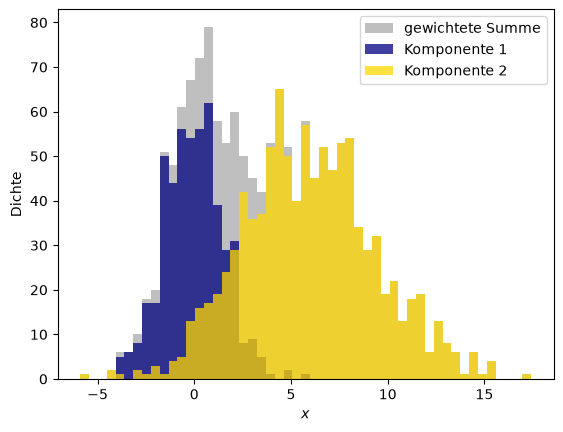

In [3]:
np.random.seed(12345)
pi = 1.0/3
real_mu_1, real_sigma_1 = 0, 1.5
real_mu_2, real_sigma_2 = 6, 3.5
component1_sample = norm.rvs(real_mu_1,
                             real_sigma_1,
                             int(pi*1500))
component2_sample = norm.rvs(real_mu_2,
                             real_sigma_2,
                             int((1-pi)*1500))
mixture_samples = np.concatenate((component1_sample,
                                  component2_sample))

fig, ax = plt.subplots()
hist = ax.hist(mixture_samples, bins=51,
               color='grey', alpha=.5,
              label="gewichtete Summe")
bins = hist[1]
ax.hist(component1_sample, alpha=.75, bins=bins,
       color='navy', label="Komponente 1")
ax.hist(component2_sample, alpha=.75, bins=bins,
       color='gold', label="Komponente 2")
ax.set_xlabel("$x$")
ax.set_ylabel("Dichte")
ax.legend()
plt.show()

In [4]:
# Initiale theta aufstellen:
pis =  np.ones(2) + np.random.random(2)
pis /= pis.sum()
mus =  np.random.random(2) * 2*np.std(mixture_samples)\
       + np.mean(mixture_samples)
sigmas =  np.sqrt(np.random.random(2) + 1)

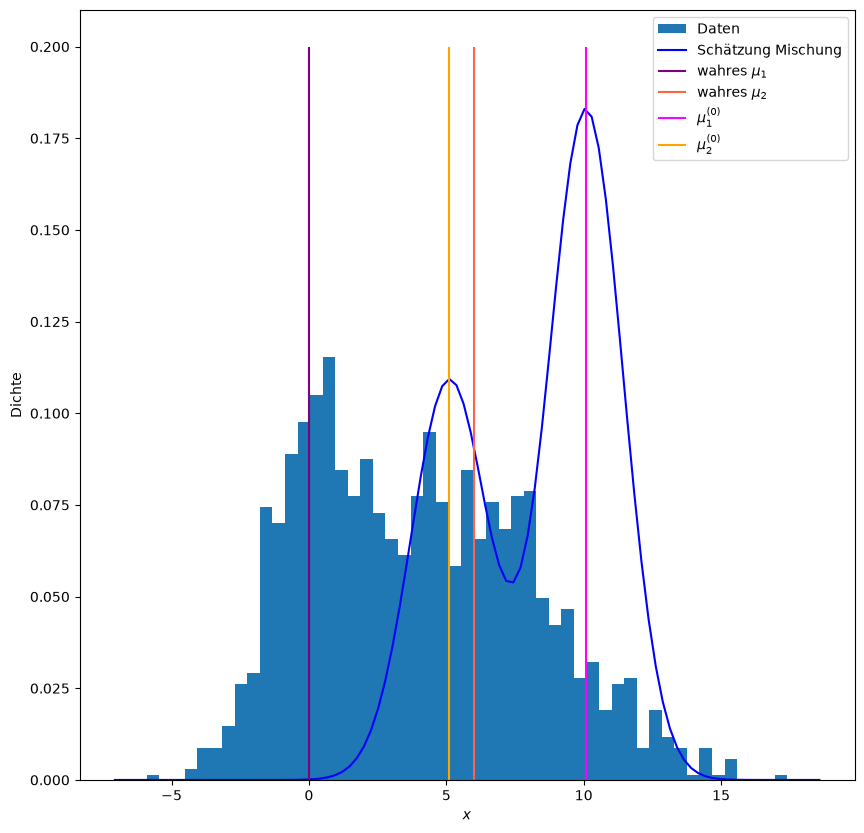

In [5]:
# Darstellung der echten Parameter vs. die initialen:
fig, ax = plt.subplots(figsize=(10,10))
hist = ax.hist(mixture_samples, bins=51,
               density=True,
               label="Daten")
xmin, xmax = ax.get_xlim()
norm_pdf_domain = np.linspace(xmin, xmax, 100)
ax.plot(norm_pdf_domain,
         pis[0]*norm.pdf(norm_pdf_domain,
                         mus[0], sigmas[0]) +
         pis[1]*norm.pdf(norm_pdf_domain,
                         mus[1], sigmas[1]),
         color='blue',
         label="Schätzung Mischung")
ax.vlines(real_mu_1, 0, .2,
          color='purple', label='wahres $\\mu_1$')
ax.vlines(real_mu_2, 0, .2,
          color='tomato', label='wahres $\\mu_2$')
ax.vlines(mus[0], 0, .2,
          color='fuchsia', label='$\\mu_1^{(0)}$')
ax.vlines(mus[1], 0, .2,
          color='orange', label='$\\mu_2^{(0)}$')
ax.set_xlabel("$x$")
ax.set_ylabel("Dichte")
ax.legend()
plt.show()

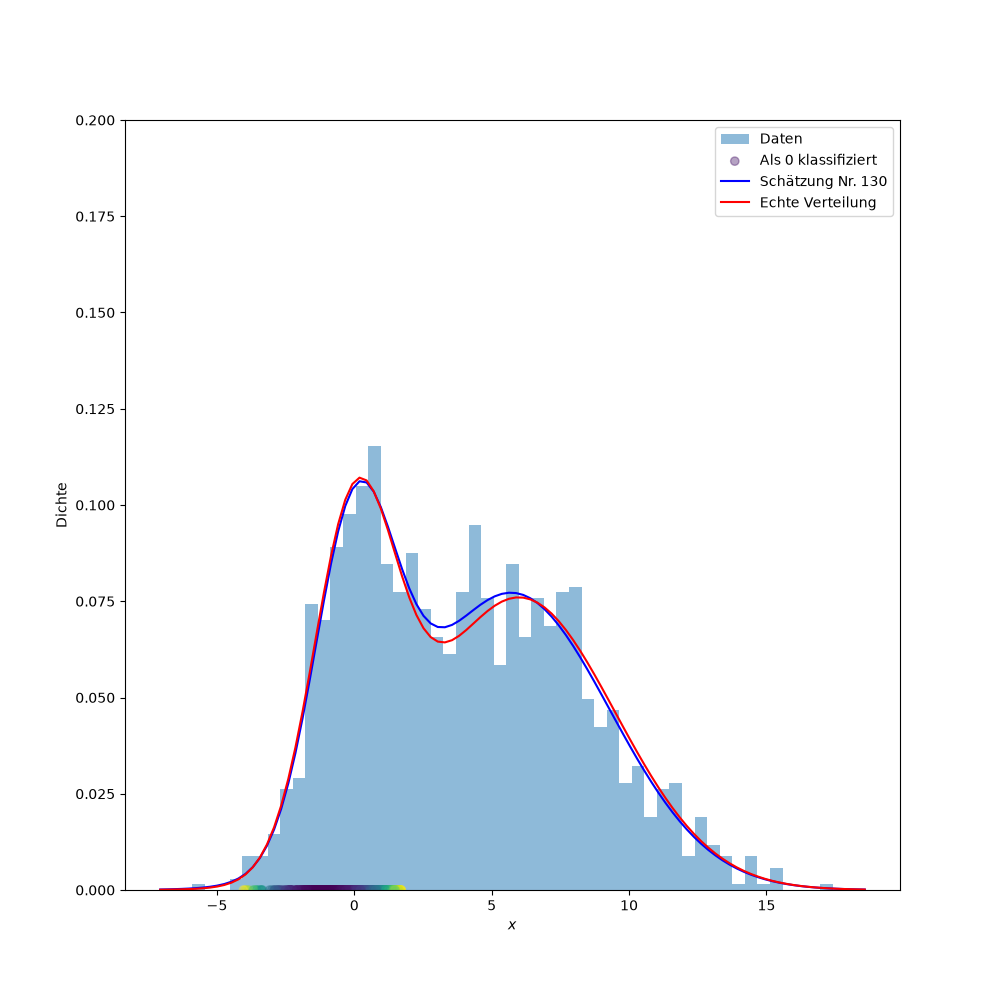

In [6]:
import matplotlib.animation as animation
from IPython import display as ipydisplay
import io, base64
from sklearn.cluster import KMeans

def init_theta(samples):
    pis = np.ones(2) / 2
    mus = np.random.random(2) * 2*np.std(samples)\
          + np.mean(samples)
    # a better way would be:
    #mus = KMeans(2).fit(samples.reshape(-1,1)).cluster_centers_
    sigmas =  np.ones(2)
    return pis, mus, sigmas

def em_iteration_draw(run_nr, ax, samples, history):
    pis, mus, sigmas, taus = history[run_nr][0:4]
    ys = np.zeros_like(samples, dtype=bool)
    if(len(taus) == len(samples)):
        for i in range(len(samples)):
            if(taus[i,1] > 0.5):
                ys[i] = 1
    ax.clear()
    ax.set_ylim(0, 0.2)
    ax.hist(samples, bins=51,
            density=True, alpha=0.5,
            label="Daten")
    if(len(taus) == len(samples)):
        ax.scatter(samples[ys], np.zeros_like(samples[ys]),
                   alpha=0.4, c=taus[ys][:,0],
                   label="Als 0 klassifiziert")
    xmin, xmax = ax.get_xlim()
    norm_pdf_domain = np.linspace(xmin, xmax, 100)
    ax.plot(norm_pdf_domain,
            pis[0]*norm.pdf(norm_pdf_domain,
                            mus[0], sigmas[0]) +
            pis[1]*norm.pdf(norm_pdf_domain,
                            mus[1], sigmas[1]),
            color='blue',
            label="Schätzung Nr. %d" % (run_nr))
    ax.plot(norm_pdf_domain,
            pi    *norm.pdf(norm_pdf_domain,
                            real_mu_1, real_sigma_1) +
            (1-pi)*norm.pdf(norm_pdf_domain,
                            real_mu_2, real_sigma_2),
            color='red',
            label="Echte Verteilung")
    ax.set_xlabel("$x$")
    ax.set_ylabel("Dichte")
    ax.legend()
    
def plot_ani(samples, history):
    fig, ax = plt.subplots(figsize=(10, 10))
    ani = animation.FuncAnimation(fig, em_iteration_draw,
                                  fargs=(ax, samples, history),
                                  interval=1000,
                                  frames=len(history))
    video = ani.to_html5_video()
    # Zusätzlich das letzte Bild als PNG ausgeben: der Web-Export zeigt das Video,
    # der PDF-Export (der kein HTML kann) verwendet das Standbild.
    png = io.BytesIO()
    fig.savefig(png, format='png')
    ipydisplay.display({'text/html': video,
                        'image/png': base64.b64encode(png.getvalue()).decode('ascii')},
                       raw=True)
    plt.close()


max_iter = 210
tol = 0.01
pis, mus, sigmas = init_theta(mixture_samples)
taus = np.zeros((len(mixture_samples), len(pis)))
# record all values in each iteration step for plotting:
history = [(pis, mus, sigmas, taus, 0)]

for i in range(max_iter):
    pis, mus, sigmas = history[-1][0:3]
    history += [EM(mixture_samples,
                   pis,
                   mus,
                   sigmas)]
    if np.abs(history[-1][-1] - history[-2][-1]) < tol:
        break
        
plot_ani(mixture_samples, history)

#### Multivariate Daten

Für den allgemeineren multivariaten Fall mühen wir uns nicht mehr mit der Herleitung ab, sondern lesen direkt den entsprechenden Code:

In [7]:
from scipy.stats import multivariate_normal as mvn

def EMmulti(xs, pis, mus, sigmas, tol=0.01, max_iter=100):
    """vectorized E-M for multivariate Gaussian mixtures"""

    n, d = xs.shape
    k = len(pis)

    ll_old = 0.0
    for i in range(max_iter):

        # (E)-Schritt
        taus = np.zeros((k, n))
        for j in range(k):
            taus[j, :] = pis[j] * mvn(mus[j], sigmas[j]).pdf(xs)
        taus /= taus.sum(axis=0)

        # (M)-Schritt
        pis = taus.sum(axis=1)
        pis /= n

        mus = np.dot(taus, xs)
        mus /= taus.sum(axis=1)[:, None]

        sigmas = np.zeros((k, d, d))
        for j in range(k):
            xcs = xs - mus[j, :]
            sigmas[j] = (taus[j,:,None,None]\
                         * np.matmul(xcs[:,:,None],
                                     xcs[:,None,:])).sum(axis=0)
        sigmas /= taus.sum(axis=1)[:,None,None]

        ll_new = 0.0
        for pi, mu, sigma in zip(pis, mus, sigmas):
            ll_new += pi * mvn(mu, sigma).pdf(xs)
        ll_new = np.log(ll_new).sum()

        if np.abs(ll_new - ll_old) < tol:
            break
        ll_old = ll_new

    return ll_new, pis, mus, sigmas

## Anwendungsbeispiele

### Aufenthaltsorte

In `data.csv` sind Aufenthaltsorte aufgezeichnet. Die Daten kommen mit der MIT-Lizenz aus [einem Blogpost](https://towardsdatascience.com/simple-gps-data-visualization-using-python-and-open-street-maps-50f992e9b676),
in dem OpenStreetMaps-Einbindung erklärt wird - das ist hier aber nicht erforderlich.

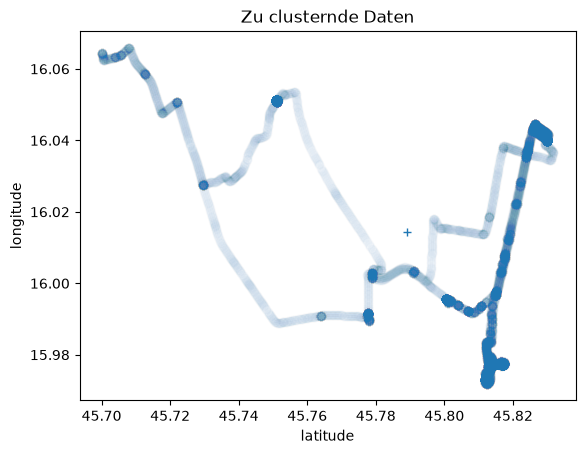

In [8]:
data = np.genfromtxt("data.csv", delimiter=',')
fig, ax = plt.subplots()
ax.scatter(data[:,0], data[:,1], alpha=0.01)
ax.set_title("Zu clusternde Daten")
ax.set_xlabel("latitude")
ax.set_ylabel("longitude")
ax.plot(np.mean(data[:,0]), np.mean(data[:,1]), marker="+")
plt.show()

Die Transformation auf Hauptkomponenten ist wenig nützlich bei diesen Daten:

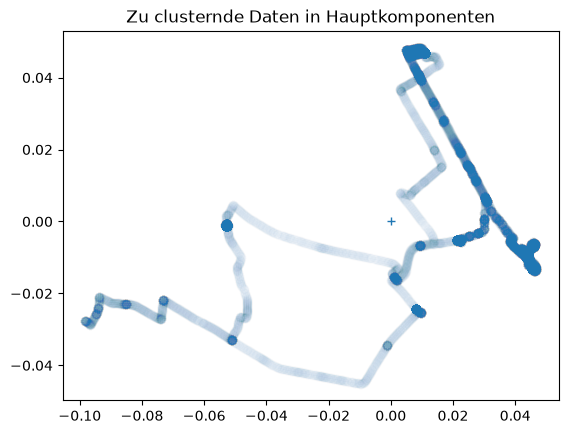

In [9]:
from sklearn.decomposition import PCA

pc = PCA().fit_transform(data)
fig, ax = plt.subplots()
ax.scatter(pc[:,0], pc[:,1], alpha=0.01)
ax.set_title("Zu clusternde Daten in Hauptkomponenten")
ax.plot(np.mean(pc[:,0]), np.mean(pc[:,1]), marker="+")
plt.show()

In [10]:
np.random.seed(1234321)
pis = np.array([0.2,0.2,0.2,0.2,0.2])
mus = np.random.random((5,2)) + np.mean(data)
sigmas = np.array([np.eye(2)] * 5)
ll_new, pis, mus, sigmas = EMmulti(data, pis, mus, sigmas)

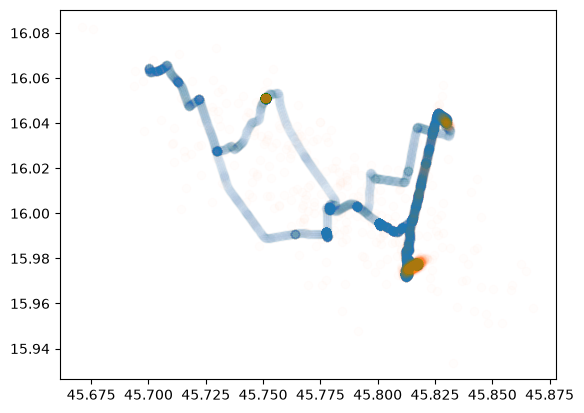

In [11]:
ys = np.concatenate([mvn(m, s).rvs(int(p*2000))
                    for p, m, s in zip(pis, mus, sigmas)])

fig, ax = plt.subplots()
ax.scatter(data[:,0],data[:,1],alpha=0.01)
ax.scatter(ys[:,0],ys[:,1],alpha=0.01)
plt.show()

Eine Interpretation wäre nun, dass wir die längeren Aufenthaltsorte damit identifiziert haben.

### Iris-Klassifikation

Wir werden jetzt die GMM (Gaussian Mixture Model)-Implementierung von Scikit-learn benutzen, um den Iris-Datensatz zu modellieren.


In [12]:
from sklearn.mixture import GaussianMixture
from sklearn.metrics import accuracy_score
from sklearn.datasets import load_iris
x, y = load_iris(return_X_y=True)
k=3

# Zum Darstellen in Hauptkomponenten transformieren:
xpc = PCA().fit_transform(x)

# Fit mit E-M-Algorithmus:
gm = GaussianMixture(n_components=k,
                     random_state=42,
                     max_iter=100,
                     init_params='k-means++',
                     verbose=1).fit(xpc)
if(gm.converged_):
    print("converged after %d steps" % gm.n_iter_)
else:
    print("could not reach convergence")

Initialization 0
  Iteration 10
Initialization converged.
converged after 19 steps


Aus dem Gausschen Mischungsmodell können wir auch die individuellen Wahrscheinlichkeiten gewinnen:

In [13]:
y_pred = gm.predict(xpc)
y_pred_proba = gm.predict_proba(xpc)
y_pred_maxproba = np.max(y_pred_proba,
                         axis = 1)

Hier wollen wir einmal die Permutation finden, die die höchste Übereinstimmung mit den tatsächlichen Klassen liefert:

In [14]:
from itertools import permutations
best_accuracy = 0.0
for permutation in permutations(range(k)):
    y_pred_permuted = np.array([permutation[value]
                                for value in y_pred])
    this_accuracy = accuracy_score(y_pred_permuted, y)
    if(this_accuracy > best_accuracy):
        best_accuracy = this_accuracy
        y_pred_bestperm = y_pred_permuted

print("Genauigkeit: %2.f%%" % (100*best_accuracy))

Genauigkeit: 97%


Und schließlich plotten, wie das Ergebnis aussieht:

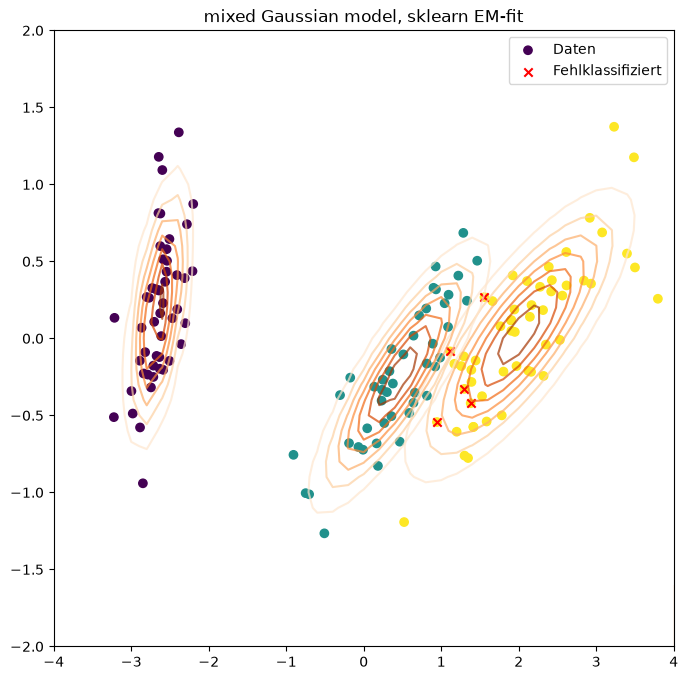

In [15]:
    
# Wir betrachten direkt die Marginalverteilungen
# in den ersten 2 Hauptkomponenten:
mvns = [mvn(mean=mu[:2],
            cov=sigma[:2,:2],
            allow_singular=True)
        for mu, sigma in zip(gm.means_,
                             gm.covariances_)]

x_wrongs = xpc[y_pred_bestperm != y]

fig, ax = plt.subplots(figsize=(8,8))
ax.set_title("mixed Gaussian model, sklearn EM-fit")
xs, ys = np.mgrid[-4:4.1:.2, -2:2.1:.1]
for i in range(k):
    zs = mvns[i].pdf(np.dstack((xs, ys)))
    ax.contour(xs, ys, zs,
               cmap=plt.cm.Oranges, alpha=.7)
ax.scatter(xpc[:,0], xpc[:,1],
           c=y_pred_bestperm, vmin=0, vmax=k-1,
           label='Daten')
ax.scatter(x_wrongs[:,0], x_wrongs[:,1],
           c='red', marker='x',
           label='Fehlklassifiziert')
ax.legend()
plt.show()

### Handgeschriebene Ziffern

Auf dem UCI ML hand-written digits Datensatz schauen wir uns an, wie gut so ein GMM funktioniert und wie man damit auch generativ neue Samples einer Klasse generiert.

In [16]:
from sklearn.datasets import load_digits
x,y = load_digits(return_X_y=True)
vargoal = .95 # keep so much of variance
pca = PCA(vargoal)
pca.fit(x)
print("kept %d of %d dimensions for %2.f%% of variance "
      % (len(pca.components_), x.shape[1], 100*vargoal))
data = pca.transform(x)

kept 29 of 64 dimensions for 95% of variance 


:::{note}
**Ausblick (nicht klausurrelevant):** Das Bayessche Informationskriterium in diesem Abschnitt ist eine von mehreren Möglichkeiten, die Anzahl der Komponenten zu wählen, und wird im Kurs nicht abgefragt.
:::

Wie viele Komponenten soll das Modell haben? Im Kapitel über Model Selection haben wir Werkzeuge für solche Fragen kennengelernt. Für Mischmodelle ist das **Bayessche Informationskriterium** (BIC) gebräuchlich: $\mathrm{BIC} = -2 \log L + m \log n$ mit der Log-Likelihood $\log L$, der Anzahl $m$ der Modellparameter und der Stichprobengröße $n$. Jede zusätzliche Komponente erhöht $m$ und muss das durch eine bessere Likelihood erst wieder hereinholen. Man wählt das $k$ mit dem kleinsten BIC:

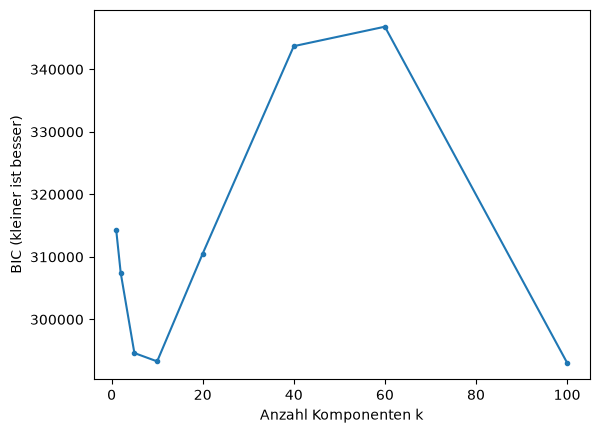

kleinstes BIC bei k = 100


In [17]:
ks = [1, 2, 5, 10, 20, 40, 60, 100]
bics = [GaussianMixture(k, random_state=23).fit(data).bic(data) for k in ks]

fig, ax = plt.subplots()
ax.plot(ks, bics, marker=".")
ax.set_xlabel("Anzahl Komponenten k")
ax.set_ylabel("BIC (kleiner ist besser)")
plt.show()
print("kleinstes BIC bei k =", ks[np.argmin(bics)])

Hier fällt das BIC bis zum größten getesteten $k$: Die Ziffern zerfallen offenbar in sehr viele kleine Cluster (verschiedene Schreibweisen derselben Ziffer), und wer das Minimum finden will, muss den Bereich weiter ausdehnen. Im Folgenden probieren wir trotzdem verschiedene $k$ von Hand aus, um zu sehen, was die einzelnen Komponenten lernen.

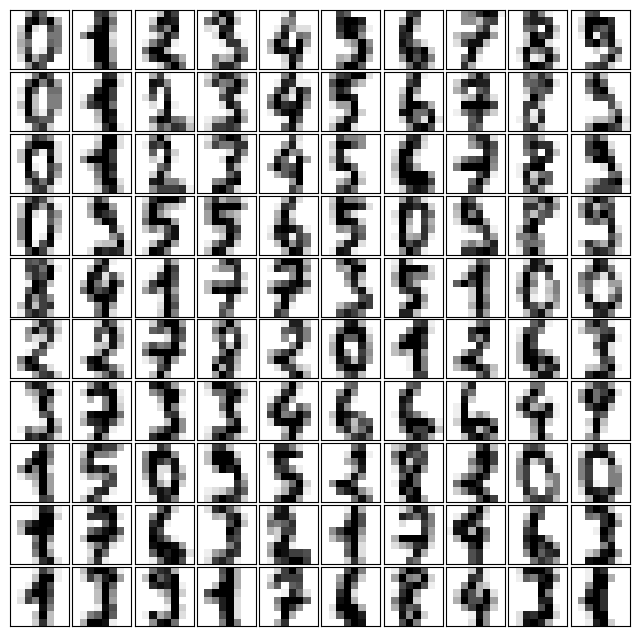

In [18]:
def plot_digits(x):
    so_many_rows = min(100, len(x)) // 10
    fig, ax = plt.subplots(so_many_rows, 10, figsize=(8, 8),
    subplot_kw=dict(xticks=[], yticks=[]))
    fig.subplots_adjust(hspace=0.05, wspace=0.05)
    for i, axi in enumerate(ax.flat):
        im = axi.imshow(x[i].reshape(8, 8), cmap='binary')
        #im.set_clim(0, 16)
    plt.show()

plot_digits(x)

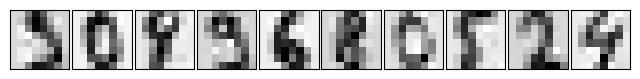

[ 1 15 24 49 57 60 62 65 68 99]


In [19]:
gm = GaussianMixture(100, random_state=23)
gm.fit(data)

new_data, new_labels = gm.sample(10)
new_data_in_old_coordinates = pca.inverse_transform(new_data)
plot_digits(new_data_in_old_coordinates)
print(new_labels)

Diese neuen Ziffern hat das GMM für uns generiert. Warum aber sind die zugehörigen Label nicht die Ziffern 0--9?

Weil wir im Training gar nicht versucht haben, pro Ziffer genau eine Normalverteilung in der Mischung zu haben. Mit den hier verwendeten 100 einzelnen Normalverteilungen klappt es aber, neue Ziffern zu generieren. Wenn wir die Klassifikation noch separat laufen lassen (etwa mit SVMs oder auch direkt als latente Variable im E-M-Algorithmus), haben wir ein Modell, mit dem wir auch gezielt neue Ziffern einer bestimmten Klasse generieren können (z.B. gezielt eine $7$).

Um etwas Einsicht in unser Modell zu gewinnen, schauen wir uns einzelne Mischungskomponenten an:

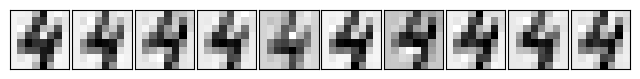

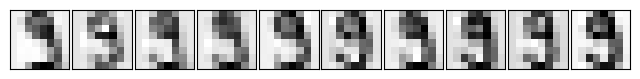

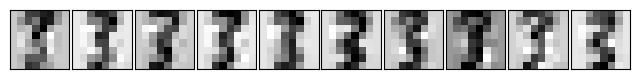

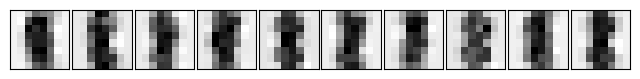

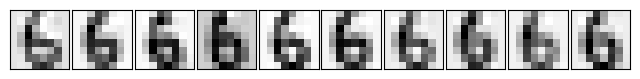

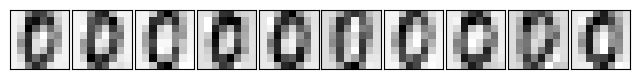

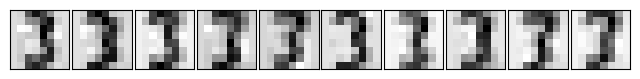

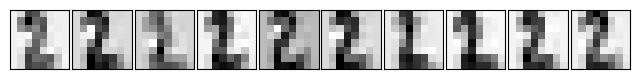

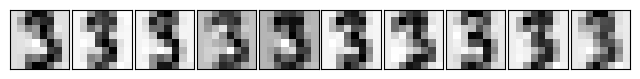

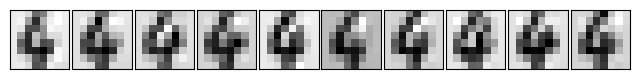

In [20]:
for i in range(10):
    mu = gm.means_[i]
    sigma = gm.covariances_[i]
    new_data = mvn(mu, sigma).rvs(10)
    new_data_in_old_coordinates = pca.inverse_transform(new_data)
    plot_digits(new_data_in_old_coordinates)

Wir sehen also durchaus, dass die Mischungskomponenten innerhalb einer Klasse bleiben, es aber eben verschiedene "Nullen" gibt. Wenn wir nur 10 Mischungskomponenten verwenden, sieht das Modell schlechter aus:

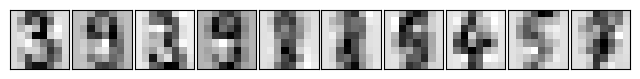

[1 1 1 1 2 2 5 7 8 9]


In [21]:
gm = GaussianMixture(10, random_state=23)
gm.fit(data)

new_data, new_labels = gm.sample(10)
new_data_in_old_coordinates = pca.inverse_transform(new_data)
plot_digits(new_data_in_old_coordinates)
print(new_labels)

Um in unserem Paradigma ohne zusätzliche Algorithmen z.B. eine $7$ zu generieren, können wir direkt auf dem Teildatensatz der $7$er trainieren:

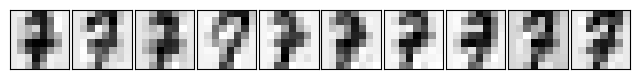

In [22]:
gm7 = GaussianMixture(10, random_state=23)
gm7.fit(data[y == 7])

new_data, new_labels = gm7.sample(10)
new_data_in_old_coordinates = pca.inverse_transform(new_data)
plot_digits(new_data_in_old_coordinates)

### Fashion-MNIST

Einfach nur weil es geht, gucken wir uns genau das gleiche auf dem Fashion-MNIST-Datensatz an:

In [23]:
from itertools import product
import numpy as np

# Der Lader steckt in fashion_mnist.py (im Ordner des Skripts) und wird auch im Kapitel
# Expectation-Maximization bzw. Model Selection verwendet. Die Daten werden nur beim ersten
# Aufruf heruntergeladen und danach aus dem Arbeitsverzeichnis gelesen.
from fashion_mnist import load_mnist

In [24]:
x_train, y_train = load_mnist(kind='train')
#x_test, y_test = load_mnist(kind='t10k')

In [25]:
def show_fashion_image(raw_data, ax):
    im = ax.imshow(raw_data.reshape(28, 28), cmap='binary')
    #im.set_clim(0, 255) # gets computed by matplotlib anyway

Wir schauen uns an, wie lange PCA.fit und EM (der gm.fit) auf diesem etwas größeren Datensatz brauchen:

In [26]:
vargoal = .90
pca = PCA(vargoal)
%timeit pca.fit(x_train)
pca.fit(x_train)

5.34 s ± 792 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",0.9
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized SV

In [27]:
print("kept %d of %d dimensions for %2.f%% of variance "
      % (len(pca.components_), x_train.shape[1], 100*vargoal))
fashion_data = pca.transform(x_train)

kept 84 of 784 dimensions for 90% of variance 


In [28]:
%%time
gm = GaussianMixture(50, random_state=23)
gm.fit(fashion_data[y_train == 1])

CPU times: user 5min 4s, sys: 299 ms, total: 5min 4s
Wall time: 26.6 s


,"n_components n_components: int, default=1The number of mixture components.",50
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to the method chosen to initialize theparameters (see `init_params`).In addition, it controls the generation of random samples from thefitted distribution (see the method `sample`).Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",23
,"covariance_type covariance_type: {'full', 'tied', 'diag', 'spherical'}, default='full'String describing the type of covariance parameters to use.Must be one of:- 'full': each component has its own general covariance matrix.- 'tied': all components share the same general covariance matrix.- 'diag': each component has its own diagonal covariance matrix.- 'spherical': each component has its own single variance.For an example of using `covariance_type`, refer to:ref:`sphx_glr_auto_examples_mixture_plot_gmm_selection.py`.",'full'
,"tol tol: float, default=1e-3The convergence threshold. EM iterations will stop when thelower bound average gain is below this threshold.",0.001
,"reg_covar reg_covar: float, default=1e-6Non-negative regularization added to the diagonal of covariance.Allows to assure that the covariance matrices are all positive.",1e-06
,"max_iter max_iter: int, default=100The number of EM iterations to perform.",100
,"n_init n_init: int, default=1The number of initializations to perform. The best results are kept.",1
,"init_params init_params: {'kmeans', 'k-means++', 'random', 'random_from_data'}, default='kmeans'The method used to initialize the weights, the means and theprecisions.String must be one of:- 'kmeans' : responsibilities are initialized using kmeans.- 'k-means++' : use the k-means++ method to initialize.- 'random' : responsibilities are initialized randomly.- 'random_from_data' : initial means are randomly selected data points... versionchanged:: v1.1 `init_params` now accepts 'random_from_data' and 'k-means++' as initialization methods.",'kmeans'
,"weights_init weights_init: array-like of shape (n_components, ), default=NoneThe user-provided initial weights.If it is None, weights are initialized using the `init_params` method.",None
,"means_init means_init: array-like of shape (n_components, n_features), default=NoneThe user-provided initial means,If it is None, means are initialized using the `init_params` method.",None
,"precisions_init precisions_init: array-like, default=NoneThe user-provided initial precisions (inverse of the covariancematrices).If it is None, precisions are initialized using the 'init_params'method.The shape depends on 'covariance_type':: (n_components,) if 'spherical', (n_features, n_features) if 'tied', (n_components, n_features) if 'diag', (n_components, n_features, n_features) if 'full'",None


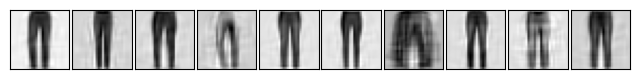

In [29]:
def draw_gm_sample(gm, pca, n=10):
    new_data, new_labels = gm.sample(n)
    new_data_in_old_coordinates = pca.inverse_transform(new_data)

    fig, axs = plt.subplots(1, len(new_data),
                            figsize=(8, 8),
                            subplot_kw=dict(xticks=[],
                                            yticks=[]))
    fig.subplots_adjust(hspace=0.05, wspace=0.05)
    for datapoint, ax in zip(new_data_in_old_coordinates, axs):
        show_fashion_image(datapoint, ax)
    plt.show()

draw_gm_sample(gm, pca, n=10)

In [30]:
%time highres_pca = PCA(.94).fit(x_train)
highres_data = highres_pca.transform(x_train)

CPU times: user 1min 1s, sys: 105 ms, total: 1min 1s
Wall time: 4.92 s


CPU times: user 2min 16s, sys: 159 ms, total: 2min 16s
Wall time: 11.3 s


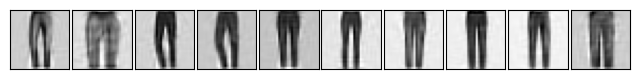

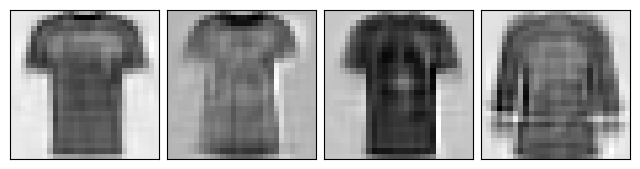

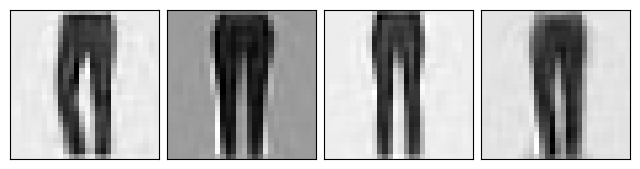

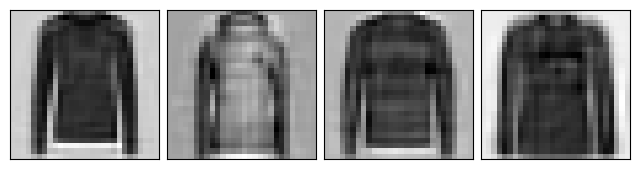

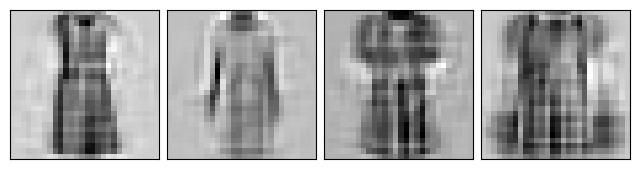

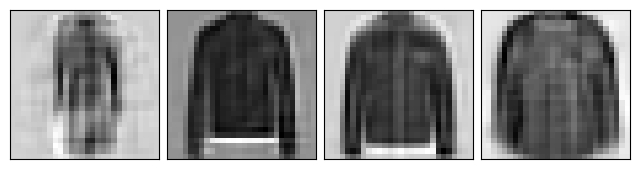

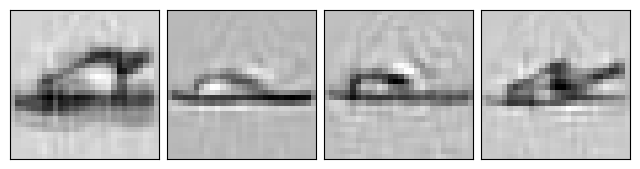

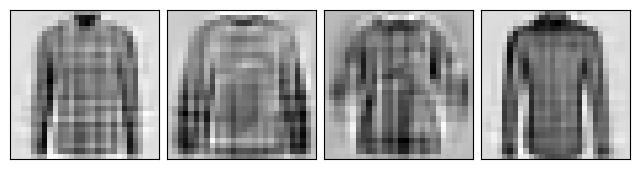

In [31]:
highres_gm = GaussianMixture(90, tol=1e-2, random_state=42)
%time highres_gm.fit(highres_data[y_train == 1])
draw_gm_sample(highres_gm, highres_pca, n=10)
for i in range(7):
    highres_gm.fit(highres_data[y_train == i])
    draw_gm_sample(highres_gm, highres_pca, n=4)

## Rückblick und Ausblick

Damit endet das Skript. Der Weg durch den Kursteil zum maschinellen Lernen war eine Kette von Ideen, die aufeinander aufbauen:

* **k-Means** war unser erstes Verfahren: Abstände messen, Punkte Zentroiden zuordnen, Zentroide neu berechnen.
* Im Kapitel über **statistische Modelle** haben wir k-Means als Maximum-Likelihood-Schätzer wiedererkannt und die Begriffe Schätzer, Bias und Likelihood eingeführt.
* **Hauptkomponentenanalyse** und **lineare Regression** waren die ersten Verfahren, die auf der Kovarianzmatrix bzw. auf der Minimierung quadratischer Abweichungen beruhen, mit Regularisierung als Mittel gegen Overfitting.
* Der **Kernel-Trick** hat gezeigt, dass viele dieser Verfahren nur Abstände oder Skalarprodukte brauchen und sich damit auf nichtlineare Strukturen übertragen lassen.
* **Statistische Tests** und **Model Selection** haben die Frage behandelt, wie man Ergebnisse und Modelle bewertet, ohne sich von der Stichprobe täuschen zu lassen: Signifikanz, Kreuzvalidierung, systematische Hyperparametersuche.
* **Expectation-Maximization** schließt den Kreis: Ein Gaußsches Mischmodell ist ein 'weiches' k-Means, das aus der Maximum-Likelihood-Methode und der Jensenschen Ungleichung folgt, und mit Kriterien wie dem BIC lässt sich sogar die Anzahl der Komponenten begründet wählen.

Bewusst nicht behandelt haben wir unter anderem neuronale Netze und Deep Learning, Zeitreihenanalyse, Reinforcement Learning, sowie alles, was nach dem Modell kommt: Deployment, Monitoring und Wartung von Modellen im Betrieb. Die Grundlagen aus diesem Skript, Wahrscheinlichkeit, Erwartungswert, Kovarianz, Likelihood, Regularisierung und Validierung, tauchen in all diesen Themen wieder auf. Die Vorlesung *Einführung in Deep Learning* setzt direkt an diesem Skript an und verwendet insbesondere Zufallsvariablen und Erwartungswert, die Kreuzentropie als Loss-Funktion, die lineare Regression als einfachstes Modell, Numpy-Shapes und Broadcasting, den Train-Test-Split mit Validierung sowie die untere Schranke $L(\theta,q)$ aus diesem Kapitel, dort ELBO genannt. Wer weiterlesen möchte, findet in {cite}`esl` und {cite}`Deisenroth2020` die mathematische Vertiefung und in {cite}`dds` die Perspektive der Praxis.